# Indian Air Quality and Weather Pattern Analysis Using Python
### College Mini-Project (Assignment 12)
**Domain:** Environmental Data Science, Meteorology, and Statistical Computing  
**Target Audience:** Undergraduate First-Year Engineering Students  
**Primary Dataset Source:** [Hugging Face: AkshayKarthick/india-weather-air-quality](https://huggingface.co/datasets/AkshayKarthick/india-weather-air-quality)  
**Temporal Window:** August 2022 to October 2026 (77,150 paired observations across 50 Indian cities)

---
## 1. Project Overview & Aim
Air pollution is one of the most pressing environmental and public health challenges facing urban India. Particulate matter ($PM_{2.5}$ and $PM_{10}$), ground-level ozone ($O_3$), nitrogen dioxide ($NO_2$), and sulfur dioxide ($SO_2$) pose severe health hazards, especially across the densely populated Indo-Gangetic Plains.

### Aim of the Project:
1. **Clean & Validate:** Process real-world daily air quality and meteorological measurements across 50 Indian cities.
2. **Numerical & Statistical Analysis:** Apply explicit NumPy and Pandas functions to calculate essential descriptive statistics (mean, median, variance, standard deviation, percentiles) and city-level rankings.
3. **Meteorological Correlation:** Evaluate how weather factors (wind speed, ambient temperature, relative humidity, precipitation) influence ground pollutant concentrations.
4. **Visual Storytelling:** Generate high-resolution, publication-quality visualizations comparing cities, longitudinal trajectories, and distributions.
5. **Reproducibility:** Provide an end-to-end, reproducible computational pipeline accessible to first-year engineering students.

## 2. Importing Required Libraries
We employ standard scientific Python libraries: **Pandas** for structured data handling, **NumPy** for vector calculations, **Matplotlib** and **Seaborn** for visualizations.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure matplotlib settings for clean inline rendering
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

print(f"Pandas version: {pd.__version__}")
print(f"NumPy version:  {np.__version__}")

Pandas version: 3.1.0
NumPy version:  2.5.4


## 3. Dataset Loading & Schema Inspection
We load the clean merged dataset generated by `src/data_cleaning.py`. This dataset links ground-level air quality observations with Open-Meteo meteorological reanalysis variables across 50 Indian cities using composite `['city', 'date']` keys.

In [2]:
data_path = os.path.join("..", "data", "processed", "india_air_quality_weather_merged.csv")
df = pd.read_csv(data_path)
df['date'] = pd.to_datetime(df['date'])

print(f"Total Observations: {len(df):,}")
print(f"Total Attributes:   {df.shape[1]}")
print(f"Date Range:         {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Unique Cities:      {df['city'].nunique()} across {df['state'].nunique()} States / UTs")
df.head(5)

Total Observations: 77,150
Total Attributes:   44
Date Range:         2022-08-05 to 2026-10-25
Unique Cities:      50 across 30 States / UTs


,date,city,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,so2_mean,o3_8h_max,co_8h_max,...,longitude,elevation_m,year,month,month_name,day,day_of_week,is_weekend,quarter,season
0,2022-08-05,Agartala,14.09,19.1,20.50,27.6,20.63,2.32,72.00,204.75,...,91.2868,12.0,2022,8,August,5,Friday,0,3,Monsoon
1,2022-08-06,Agartala,12.12,19.3,17.44,27.7,23.11,1.10,48.00,208.00,...,91.2868,12.0,2022,8,August,6,Saturday,1,3,Monsoon
2,2022-08-07,Agartala,11.85,19.0,17.18,27.6,22.27,1.18,75.00,238.38,...,91.2868,12.0,2022,8,August,7,Sunday,1,3,Monsoon
3,2022-08-08,Agartala,9.28,13.5,13.47,19.5,16.25,1.10,65.25,241.38,...,91.2868,12.0,2022,8,August,8,Monday,0,3,Monsoon
4,2022-08-09,Agartala,6.33,7.4,9.25,10.8,11.51,1.28,69.38,181.88,...,91.2868,12.0,2022,8,August,9,Tuesday,0,3,Monsoon


## 4. Verification of Data Cleaning & Null Values
A critical step in any data science workflow is ensuring that the data contains no invalid null values, negative physical concentrations, or unhandled outliers.

In [3]:
key_columns = [
    'pm2_5_mean', 'pm10_mean', 'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max', 'india_aqi',
    'temperature_2m_mean', 'relative_humidity_2m_mean', 'wind_speed_10m_max', 'precipitation_sum'
]

null_summary = df[key_columns].isnull().sum().to_frame(name='Missing Count')
null_summary['Missing Percentage (%)'] = (null_summary['Missing Count'] / len(df)) * 100
print("=== Missing Value Verification (Post-Cleaning) ===")
display(null_summary)

=== Missing Value Verification (Post-Cleaning) ===


,Missing Count,Missing Percentage (%)
pm2_5_mean,0,0.0
pm10_mean,0,0.0
no2_mean,0,0.0
so2_mean,0,0.0
o3_8h_max,0,0.0
co_8h_max,0,0.0
india_aqi,0,0.0
temperature_2m_mean,0,0.0
relative_humidity_2m_mean,0,0.0
wind_speed_10m_max,0,0.0


## 5. Explicit Numerical Analysis using NumPy & Pandas
### Beginner-Friendly Mathematical Formulations:
1. **Sample Mean (Arithmetic Average):**
$$\bar{x} = \frac{1}{N}\sum_{i=1}^{N} x_i$$
*Purpose:* Measures the central tendency of the concentration across all monitoring days.

2. **Sample Variance ($s^2$) with Bessel's Correction ($N-1$):**
$$s^2 = \frac{1}{N-1}\sum_{i=1}^{N} (x_i - \bar{x})^2$$
*Purpose:* Measures how widely daily pollutant values disperse around the mean.

3. **Sample Standard Deviation ($s$):**
$$s = \sqrt{s^2}$$
*Purpose:* Expresses dispersion in the original units (e.g., $\mu g/m^3$).

4. **Percentiles ($P_{25}, P_{50}, P_{75}, P_{90}, P_{95}, P_{99}$):**
*Purpose:* $P_{50}$ is the Median. $P_{95}$ reveals the acute peak pollution levels experienced on the most hazardous 5% of days.

In [4]:
stats_records = []
for col in key_columns:
    arr = df[col].to_numpy()
    stats_records.append({
        'Variable': col,
        'Mean': np.round(np.mean(arr), 2),
        'Median (P50)': np.round(np.median(arr), 2),
        'Min': np.round(np.min(arr), 2),
        'Max': np.round(np.max(arr), 2),
        'Variance': np.round(np.var(arr, ddof=1), 2),
        'Std Dev': np.round(np.std(arr, ddof=1), 2),
        'P25': np.round(np.percentile(arr, 25), 2),
        'P75': np.round(np.percentile(arr, 75), 2),
        'P90': np.round(np.percentile(arr, 90), 2),
        'P95': np.round(np.percentile(arr, 95), 2),
    })

stats_df = pd.DataFrame(stats_records)
print("=== Descriptive Statistical Summary Computed via NumPy ===")
display(stats_df)

=== Descriptive Statistical Summary Computed via NumPy ===


,Variable,Mean,Median (P50),Min,Max,Variance,Std Dev,P25,P75,P90,P95
0,pm2_5_mean,35.49,28.10,0.48,279.78,785.65,28.03,16.72,45.33,70.06,91.28
1,pm10_mean,56.29,41.35,0.62,1788.14,3928.30,62.68,24.82,67.40,108.02,146.29
2,no2_mean,15.56,11.72,0.00,156.98,181.05,13.46,6.98,19.73,31.03,40.96
3,so2_mean,13.14,7.81,0.03,505.24,397.22,19.93,4.03,14.46,27.18,42.23
4,o3_8h_max,123.25,125.62,17.88,715.88,1640.29,40.50,96.38,149.12,169.62,182.62
5,co_8h_max,588.91,465.25,59.25,10595.50,227314.20,476.77,309.38,696.50,1074.76,1444.50
6,india_aqi,145.88,140.00,28.00,500.00,4311.53,65.66,98.00,178.00,225.00,276.00
7,temperature_2m_mean,24.42,26.00,-15.40,40.30,44.17,6.65,21.80,28.50,30.80,32.50
8,relative_humidity_2m_mean,67.98,72.00,6.00,99.00,334.67,18.29,57.00,83.00,88.00,90.00
9,wind_speed_10m_max,14.40,13.70,2.40,56.70,28.43,5.33,10.40,17.70,21.60,24.10


## 6. City-Wise Rankings: Top 10 Most Polluted vs Top 10 Cleanest Cities
We aggregate by city to discover which urban regions consistently face the highest particulate loads compared to the national ambient air quality standard (CPCB NAAQS Annual Limit = $40\,\mu g/m^3$).

In [5]:
city_stats = df.groupby(['city', 'state', 'region']).agg(
    Observations=('date', 'count'),
    PM2_5_Mean=('pm2_5_mean', 'mean'),
    PM10_Mean=('pm10_mean', 'mean'),
    AQI_Mean=('india_aqi', 'mean'),
    Temp_Mean=('temperature_2m_mean', 'mean'),
    Wind_Mean=('wind_speed_10m_max', 'mean')
).round(2).reset_index()

top10_polluted = city_stats.sort_values(by='PM2_5_Mean', ascending=False).head(10)
top10_cleanest = city_stats.sort_values(by='PM2_5_Mean', ascending=True).head(10)

print("=== TOP 10 MOST POLLUTED CITIES (Mean PM2.5 in µg/m³) ===")
display(top10_polluted[['city', 'state', 'region', 'PM2_5_Mean', 'PM10_Mean', 'AQI_Mean']])

print("=== TOP 10 CLEANEST CITIES (Mean PM2.5 in µg/m³) ===")
display(top10_cleanest[['city', 'state', 'region', 'PM2_5_Mean', 'PM10_Mean', 'AQI_Mean']])

=== TOP 10 MOST POLLUTED CITIES (Mean PM2.5 in µg/m³) ===


,city,state,region,PM2_5_Mean,PM10_Mean,AQI_Mean
11,Delhi,Delhi,North,74.21,162.93,235.75
1,Agra,Uttar Pradesh,North,69.57,195.75,233.84
3,Amritsar,Punjab,North,65.44,95.93,203.95
26,Ludhiana,Punjab,North,64.83,104.33,194.59
34,Patna,Bihar,East,61.15,82.67,200.17
23,Kolkata,West Bengal,East,57.72,74.68,182.56
25,Lucknow,Uttar Pradesh,North,57.71,94.12,187.43
36,Prayagraj,Uttar Pradesh,North,56.95,83.81,189.95
21,Kanpur,Uttar Pradesh,North,56.34,117.28,194.33
47,Varanasi,Uttar Pradesh,North,56.20,80.74,188.30


=== TOP 10 CLEANEST CITIES (Mean PM2.5 in µg/m³) ===


,city,state,region,PM2_5_Mean,PM10_Mean,AQI_Mean
24,Leh,Ladakh,North,4.92,9.56,144.12
35,Port Blair,Andaman and Nicobar Islands,South,10.57,17.22,81.57
45,Thiruvananthapuram,Kerala,South,17.07,26.51,113.38
9,Coimbatore,Tamil Nadu,South,17.89,24.16,108.88
30,Mysuru,Karnataka,South,18.47,25.25,115.30
12,Gangtok,Sikkim,Northeast,19.83,25.99,122.40
41,Shillong,Meghalaya,Northeast,19.92,26.77,119.21
37,Puducherry,Puducherry,South,20.43,30.47,121.66
4,Bengaluru,Karnataka,South,20.81,28.29,113.14
42,Shimla,Himachal Pradesh,North,21.60,31.83,142.95


## 7. Meteorological Influences & Correlation Analysis
### Scientific Reminder: Correlation is NOT Causation!
The **Pearson Correlation Coefficient ($r$)** measures linear association:
$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2 \sum (y_i - \bar{y})^2}}$$
- $r = -0.313$ (Wind Speed vs $PM_{2.5}$): A negative correlation means higher winds enhance horizontal dispersion and ventilation, diluting surface particulate density.
- $r = -0.225$ (Precipitation vs $PM_{2.5}$): Rain wash-out (wet scavenging) removes airborne particulates.
- $r = -0.172$ (Temperature vs $PM_{2.5}$): Cold winter conditions provoke low boundary layer thermal inversions that trap smoke and dust near ground level.

In [6]:
corr_matrix = df[key_columns].corr(method='pearson').round(3)
print("=== Pearson Correlation Matrix (Key Variables) ===")
display(corr_matrix)

=== Pearson Correlation Matrix (Key Variables) ===


,pm2_5_mean,pm10_mean,no2_mean,so2_mean,o3_8h_max,co_8h_max,india_aqi,temperature_2m_mean,relative_humidity_2m_mean,wind_speed_10m_max,precipitation_sum
pm2_5_mean,1.000,0.692,0.598,0.441,0.536,0.705,0.744,-0.172,-0.093,-0.313,-0.225
pm10_mean,0.692,1.000,0.338,0.256,0.382,0.384,0.680,0.039,-0.225,-0.105,-0.169
no2_mean,0.598,0.338,1.000,0.680,0.270,0.737,0.385,-0.108,-0.112,-0.265,-0.141
so2_mean,0.441,0.256,0.680,1.000,0.112,0.418,0.255,0.021,-0.083,-0.090,-0.089
o3_8h_max,0.536,0.382,0.270,0.112,1.000,0.371,0.860,-0.010,-0.426,-0.279,-0.314
co_8h_max,0.705,0.384,0.737,0.418,0.371,1.000,0.489,-0.273,-0.022,-0.337,-0.158
india_aqi,0.744,0.680,0.385,0.255,0.860,0.489,1.000,-0.032,-0.373,-0.268,-0.290
temperature_2m_mean,-0.172,0.039,-0.108,0.021,-0.010,-0.273,-0.032,1.000,-0.077,0.403,0.035
relative_humidity_2m_mean,-0.093,-0.225,-0.112,-0.083,-0.426,-0.022,-0.373,-0.077,1.000,-0.016,0.406
wind_speed_10m_max,-0.313,-0.105,-0.265,-0.090,-0.279,-0.337,-0.268,0.403,-0.016,1.000,0.152


## 8. Visualizations Suite
Here we display the five core analytical figures developed for this project.

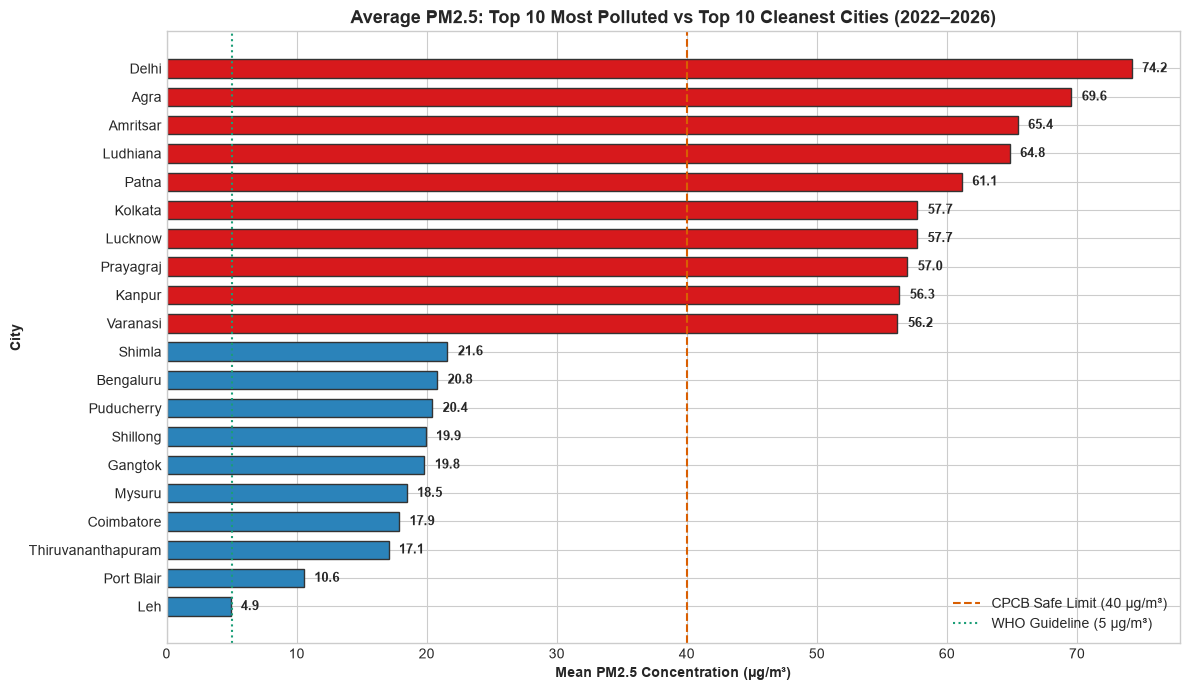

In [7]:
# Graph 1: City PM2.5 Comparison
combined = pd.concat([top10_polluted, top10_cleanest]).sort_values(by='PM2_5_Mean', ascending=True)
fig, ax = plt.subplots(figsize=(12, 7))
colors = ['#2b83ba' if x < 25 else '#d7191c' for x in combined['PM2_5_Mean']]
bars = ax.barh(combined['city'], combined['PM2_5_Mean'], color=colors, edgecolor='#333333', height=0.65)
ax.axvline(40, color='#d95f02', linestyle='--', linewidth=1.5, label='CPCB Safe Limit (40 µg/m³)')
ax.axvline(5, color='#1b9e77', linestyle=':', linewidth=1.5, label='WHO Guideline (5 µg/m³)')
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.8, bar.get_y() + bar.get_height()/2, f"{w:.1f}", va='center', fontsize=9, fontweight='bold')
ax.set_title('Average PM2.5: Top 10 Most Polluted vs Top 10 Cleanest Cities (2022–2026)', fontsize=13, fontweight='bold')
ax.set_xlabel('Mean PM2.5 Concentration (µg/m³)', fontweight='bold')
ax.set_ylabel('City', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

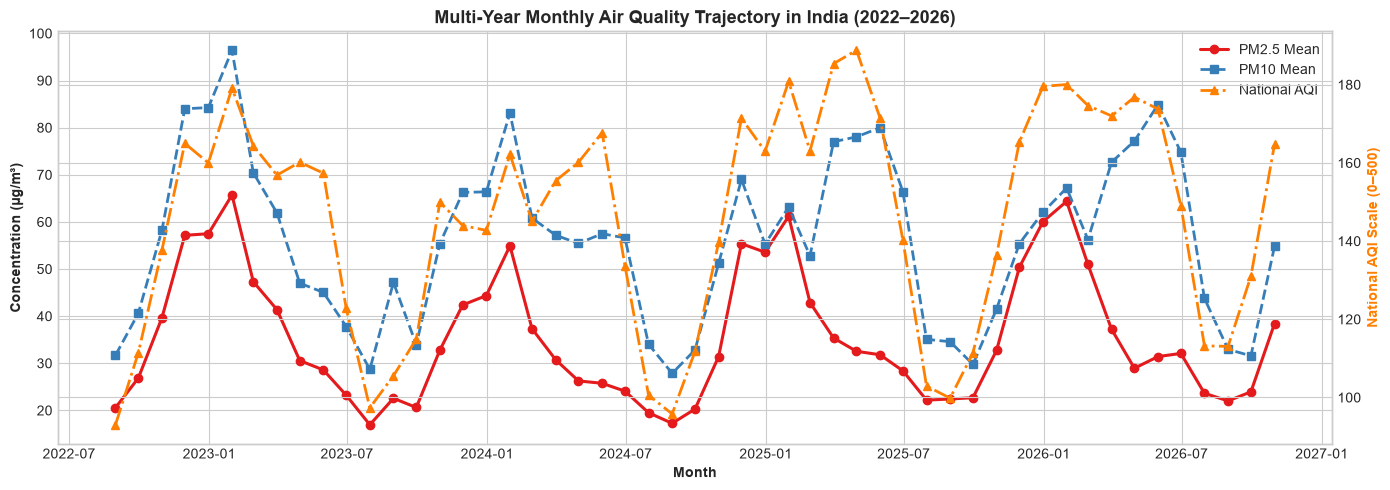

In [8]:
# Graph 2: Longitudinal Time-Series Dynamics
monthly_series = df.set_index('date').resample('ME')[['pm2_5_mean', 'pm10_mean', 'india_aqi']].mean().reset_index()
fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(monthly_series['date'], monthly_series['pm2_5_mean'], color='#e41a1c', marker='o', linewidth=2.2, label='PM2.5 Mean')
ax1.plot(monthly_series['date'], monthly_series['pm10_mean'], color='#377eb8', marker='s', linewidth=2.0, linestyle='--', label='PM10 Mean')
ax1.set_ylabel('Concentration (µg/m³)', fontweight='bold')
ax1.set_xlabel('Month', fontweight='bold')
ax2 = ax1.twinx()
ax2.plot(monthly_series['date'], monthly_series['india_aqi'], color='#ff7f00', marker='^', linewidth=2.0, linestyle='-.', label='National AQI')
ax2.set_ylabel('National AQI Scale (0–500)', color='#ff7f00', fontweight='bold')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
ax1.set_title('Multi-Year Monthly Air Quality Trajectory in India (2022–2026)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

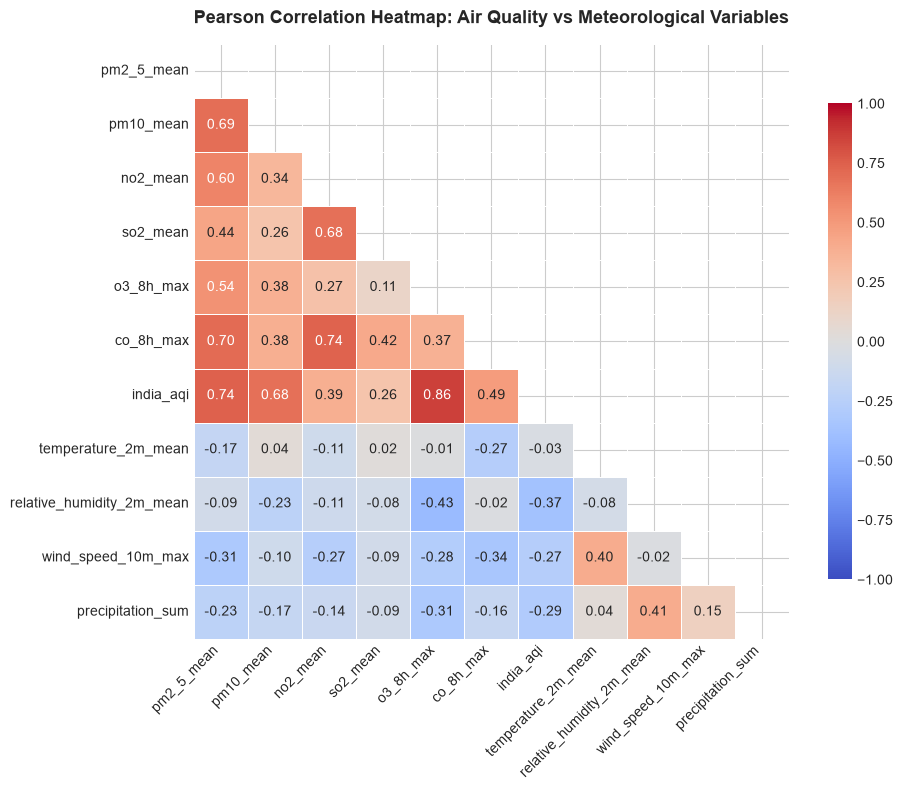

In [9]:
# Graph 3: Correlation Heatmap
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Pearson Correlation Heatmap: Air Quality vs Meteorological Variables', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 9. Academic Conclusions & Engineering Takeaways
1. **Indo-Gangetic Basin Vulnerability:** The top 10 most polluted cities (Delhi, Agra, Amritsar, Ludhiana, Patna, Kolkata, Lucknow, Prayagraj, Kanpur, Varanasi) are concentrated in northern and eastern river plains where geography, high population density, and stagnant winter meteorology trap emissions.
2. **Natural Coastal and Hill Sanctuary:** High-altitude and coastal southern cities (Leh, Port Blair, Thiruvananthapuram, Coimbatore, Mysuru, Gangtok) exhibit PM2.5 levels compliant with CPCB limits due to high maritime ventilation and absence of industrial trapping.
3. **Predictable Seasonal Cycles:** Air quality follows a strong periodic cycle: severe pollution during winter (Nov–Jan) and minimum particulate levels during the southwest monsoon (Jul–Sep).
4. **Actionable Policy Implications:** Mitigation strategies (dust suppression, electric mass transit, industrial scrubbing) must be intensified proactively before the onset of winter inversion.